<a href="https://colab.research.google.com/github/mominanoor/Machine-Learning/blob/main/Transcend_EMBER2024_APK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Setup 1: EMBER2024 clone aur thrember install
!git clone https://github.com/FutureComputing4AI/EMBER2024.git
%cd EMBER2024
!pip install -q .

Cloning into 'EMBER2024'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 69 (delta 0), reused 0 (delta 0), pack-reused 67 (from 1)
Receiving objects: 100% (69/69), 42.68 KiB | 4.74 MiB/s, done.
Resolving deltas: 100% (22/22), done.
/content/EMBER2024
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 62.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.5/88.5 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.0/105.0 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.6/194.6 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# Setup 2: oscrypto fix install
!pip install -q -I git+https://github.com/wbond/oscrypto.git@d5f3437ed24257895ae1edd9e503cfb352e635a8

  Preparing metadata (setup.py) ... done


In [ ]:
# Setup 3: thrember features.py patch
import re
path = "/usr/local/lib/python3.13/dist-packages/thrember/features.py"
src = open(path).read()
src = src.replace(
    "from signify.authenticode import SignedPEFile",
    "try:\n    from signify.authenticode import SignedPEFile\nexcept ImportError:\n    SignedPEFile = None"
)
open(path, "w").write(src)
print("patched")

patched


In [ ]:
# Setup 4: thrember import aur disk check
import thrember
print("OK, thrember load ho gaya")
!df -h /content | tail -1

OK, thrember load ho gaya
overlay         108G   21G   88G  20% /


In [ ]:
# Data 1: APK dataset download
import os, thrember
os.makedirs("/content/ember_data", exist_ok=True)
thrember.download_dataset("/content/ember_data", file_type="APK")
print("download complete")

APK_train.zip: reconstructing file:   0%|          |  0.00B /  784MB            

APK_train.zip: downloading bytes:           |  0.00B            

Unzipping...


APK_test.zip: reconstructing file:   0%|          |  0.00B /  177MB            

APK_test.zip: downloading bytes:           |  0.00B            

Unzipping...


challenge.zip: reconstructing file:   0%|          |  0.00B / 32.1MB            

challenge.zip: downloading bytes:           |  0.00B            

download complete


In [ ]:
#Data 2: Downloaded files ki list
!find /content/ember_data -type f | head -30
!du -sh /content/ember_data
print([n for n in dir(thrember) if not n.startswith("_")])

/content/ember_data/2023-12-24_2023-12-30_APK_train.jsonl
/content/ember_data/2024-03-10_2024-03-16_APK_train.jsonl
/content/ember_data/2024-03-10_2024-03-16_challenge_malicious.jsonl
/content/ember_data/2024-07-28_2024-08-03_challenge_malicious.jsonl
/content/ember_data/2023-11-05_2023-11-11_APK_train.jsonl
/content/ember_data/2024-02-11_2024-02-17_challenge_malicious.jsonl
/content/ember_data/2024-06-02_2024-06-08_challenge_malicious.jsonl
/content/ember_data/2024-05-26_2024-06-01_challenge_malicious.jsonl
/content/ember_data/2024-04-21_2024-04-27_challenge_malicious.jsonl
/content/ember_data/2024-03-17_2024-03-23_APK_train.jsonl
/content/ember_data/2024-06-16_2024-06-22_APK_train.jsonl
/content/ember_data/2024-08-18_2024-08-24_APK_train.jsonl
/content/ember_data/2024-04-14_2024-04-20_challenge_malicious.jsonl
/content/ember_data/2024-01-28_2024-02-03_APK_train.jsonl
/content/ember_data/2024-04-07_2024-04-13_APK_train.jsonl
/content/ember_data/2024-08-11_2024-08-17_challenge_maliciou

In [ ]:
# Data 3: Dataset structure inspect
import inspect, glob, json, thrember

for fn in [thrember.create_vectorized_features, thrember.vectorize_subset,
           thrember.read_vectorized_features, thrember.read_metadata]:
    print("=" * 70)
    print(fn.__name__, inspect.signature(fn))
    print(inspect.getdoc(fn))

files = sorted(glob.glob("/content/ember_data/*APK_train.jsonl"))
tests = sorted(glob.glob("/content/ember_data/*APK_test.jsonl"))
print("\ntrain weeks:", len(files), " test weeks:", len(tests))
print("first train:", files[0].split('/')[-1], " last train:", files[-1].split('/')[-1])
print("first test :", tests[0].split('/')[-1], " last test :", tests[-1].split('/')[-1])

with open(files[0]) as f:
    rec = json.loads(f.readline())
print("\nrecord keys:", list(rec.keys()))
print({k: (str(v)[:80]) for k, v in rec.items()})

create_vectorized_features (data_dir: pathlib._local.Path | str, label_type: str = 'label', class_min: int = 10) -> None
Create feature vectors from raw features and write them to disk

Arguments:
data_dir - Path to the directory containing the dataset.
label_type - The type of classification problem.
class_min - The minimum number of instances of a class in the dataset. Data
            points belonging to a class with fewer than class_min instances
            are ignored.

Valid label_types:
label - malicious/benign (binary)
family - malware family classification (multiclass)
behavior - malware behavior prediction (multiclass, multi-label)
file_property - malware file property prediction (multiclass, multi-label)
packer - malware packer prediction (multiclass, multi-label)
exploit - malware exploit prediction (multiclass, multi-label)
group - malware threat group prediction (multiclass, multi-label)
vectorize_subset (X_path: pathlib._local.Path, y_path: pathlib._local.Path, raw_feat

In [ ]:
# Features 1: Chhota sample (apk_feats.npz)
import glob, json, numpy as np, time
rng = np.random.default_rng(0)
DIR = "/content/ember_data"

def layout_from(rec):
    L = {}
    for sec in ("strings", "general"):
        L[sec] = []
        for k in sorted(rec[sec]):
            v = rec[sec][k]
            if isinstance(v, (int, float)): L[sec].append((k, 1))
            elif isinstance(v, list) and v and all(isinstance(t, (int, float)) for t in v):
                L[sec].append((k, len(v)))
    return L

def vec(rec):
    out = []
    for key in ("histogram", "byteentropy"):
        a = np.asarray(rec[key], dtype=np.float64); s = a.sum()
        out.append(a / s if s > 0 else a)
    for sec in ("strings", "general"):
        d = rec[sec]
        for k, n in LAYOUT[sec]:
            v = d.get(k)
            if n == 1:
                x = float(v) if isinstance(v, (int, float)) else 0.0
                out.append(np.array([np.sign(x) * np.log1p(abs(x))]))
            else:
                a = np.zeros(n)
                if isinstance(v, list):
                    m = min(n, len(v)); a[:m] = np.asarray(v[:m], float)
                s = a.sum(); out.append(a / s if s > 0 else a)
    return np.concatenate(out)

train_files = sorted(glob.glob(f"{DIR}/*APK_train.jsonl"))
test_files  = sorted(glob.glob(f"{DIR}/*APK_test.jsonl"))
with open(train_files[0]) as f: LAYOUT = layout_from(json.loads(f.readline()))
print("layout:", {s: len(v) for s, v in LAYOUT.items()})

def build(files, frac):
    X, y, w = [], [], []
    t0 = time.time()
    for wi, fn in enumerate(files):
        with open(fn) as fh:
            for line in fh:
                if rng.random() > frac: continue
                r = json.loads(line)
                X.append(vec(r).astype(np.float32)); y.append(int(r["label"])); w.append(wi)
        print(f"week {wi+1}/{len(files)} done, rows so far {len(y)}, {time.time()-t0:.0f}s")
    return np.array(X), np.array(y), np.array(w)

Xtr, ytr, wtr = build(train_files, 0.25)   # ~1000 per train week
Xte, yte, wte = build(test_files, 0.5)     # ~2000 per test week
np.savez_compressed("/content/apk_feats.npz", Xtr=Xtr, ytr=ytr, wtr=wtr, Xte=Xte, yte=yte, wte=wte)
print("train", Xtr.shape, np.unique(ytr, return_counts=True))
print("test ", Xte.shape, np.unique(yte, return_counts=True))
print("malware ratio per test week:", [round(float(yte[wte == i].mean()), 2) for i in range(12)])

layout: {'strings': 5, 'general': 4}
week 1/52 done, rows so far 2043, 1s
week 2/52 done, rows so far 3939, 2s
week 3/52 done, rows so far 5876, 3s
week 4/52 done, rows so far 7915, 3s
week 5/52 done, rows so far 9880, 4s
week 6/52 done, rows so far 11937, 5s
week 7/52 done, rows so far 13925, 6s
week 8/52 done, rows so far 15952, 6s
week 9/52 done, rows so far 17929, 7s
week 10/52 done, rows so far 19971, 7s
week 11/52 done, rows so far 21973, 7s
week 12/52 done, rows so far 23975, 8s
week 13/52 done, rows so far 26043, 8s
week 14/52 done, rows so far 28006, 9s
week 15/52 done, rows so far 30000, 9s
week 16/52 done, rows so far 31962, 10s
week 17/52 done, rows so far 33979, 11s
week 18/52 done, rows so far 35990, 11s
week 19/52 done, rows so far 37895, 12s
week 20/52 done, rows so far 39912, 12s
week 21/52 done, rows so far 41907, 12s
week 22/52 done, rows so far 43879, 13s
week 23/52 done, rows so far 45881, 13s
week 24/52 done, rows so far 47927, 14s
week 25/52 done, rows so far 499

[    2s] loaded (104102, 619), (47825, 619)
[    3s] scaled
[  366s] SVM trained


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


[ 1348s] Platt trained
calibration F1 (no filter): 0.849
[ 1349s] threshold search 1 done
[ 1349s] threshold search 2 done
p-value thr: benign 0.271 malicious 0.271 | kept 0.80 F1 0.912
prob.   thr: benign 0.639 malicious 0.639 | kept 0.80 F1 0.910
week  1 | F1 all 0.825 | Transcend F1 0.890 kept 0.805 | Prob F1 0.890 kept 0.801 | discarded F1: PV 0.556 Prob 0.562 | mean p 0.554
week  2 | F1 all 0.817 | Transcend F1 0.884 kept 0.815 | Prob F1 0.886 kept 0.811 | discarded F1: PV 0.518 Prob 0.519 | mean p 0.576
week  3 | F1 all 0.809 | Transcend F1 0.875 kept 0.786 | Prob F1 0.881 kept 0.785 | discarded F1: PV 0.561 Prob 0.543 | mean p 0.545
week  4 | F1 all 0.844 | Transcend F1 0.894 kept 0.808 | Prob F1 0.894 kept 0.807 | discarded F1: PV 0.634 Prob 0.633 | mean p 0.553
week  5 | F1 all 0.845 | Transcend F1 0.888 kept 0.814 | Prob F1 0.888 kept 0.814 | discarded F1: PV 0.651 Prob 0.654 | mean p 0.575
week  6 | F1 all 0.827 | Transcend F1 0.882 kept 0.797 | Prob F1 0.885 kept 0.795 | di

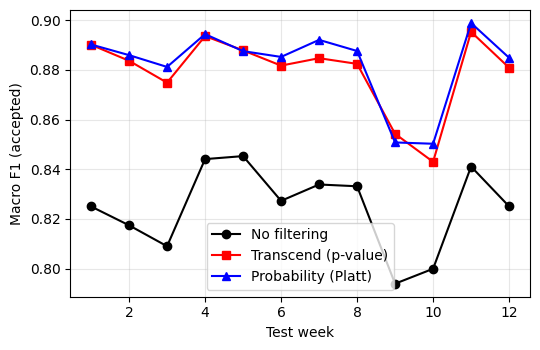

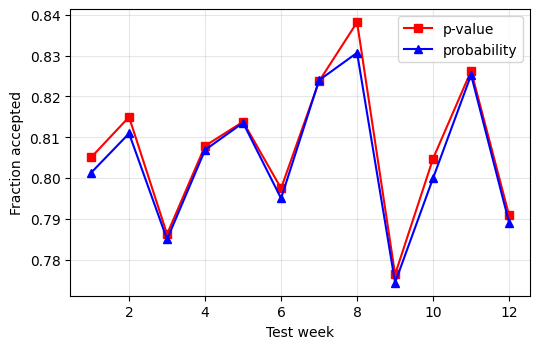

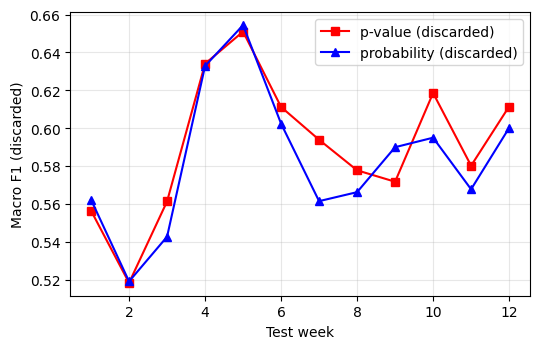

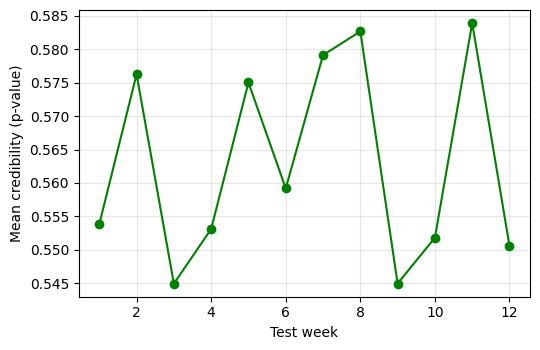

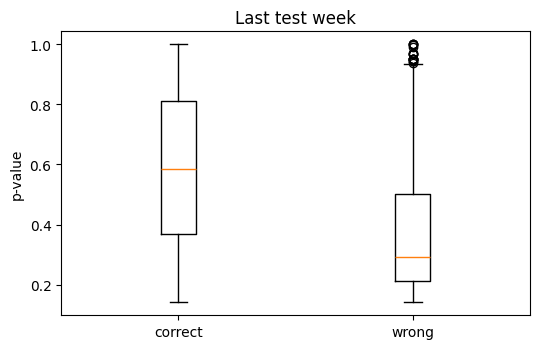

In [ ]:
# Features: Poora dataset (apk_feats_full.npz)
import numpy as np, matplotlib.pyplot as plt, time
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
rng = np.random.default_rng(0); t0 = time.time()
def log(m): print(f"[{time.time()-t0:5.0f}s] {m}", flush=True)

d = np.load("/content/apk_feats.npz")
Xtr_all, ytr_all, Xte, yte, wte = d["Xtr"], d["ytr"], d["Xte"], d["yte"], d["wte"]
log(f"loaded {Xtr_all.shape}, {Xte.shape}")

idx = rng.permutation(len(Xtr_all))[:40000]; nc = 4000
cal_i, tr_i = idx[:nc], idx[nc:]
sc = StandardScaler().fit(Xtr_all[tr_i])
Xtr, ytr = sc.transform(Xtr_all[tr_i]), ytr_all[tr_i]
Xcal, ycal = sc.transform(Xtr_all[cal_i]), ytr_all[cal_i]
Xte = sc.transform(Xte); log("scaled")

svm = LinearSVC(C=0.1, max_iter=1000, dual=False).fit(Xtr, ytr); log("SVM trained")
platt = CalibratedClassifierCV(LinearSVC(C=0.1, max_iter=1000, dual=False), cv=3).fit(Xtr, ytr); log("Platt trained")

def ncm(X, l):
    s = svm.decision_function(X); return -s if l == 1 else s
cal_a = {l: np.sort(ncm(Xcal[ycal == l], l)) for l in (0, 1)}
def pval(X, pred):
    p = np.zeros(len(X))
    for l in (0, 1):
        m = pred == l
        if m.any():
            a = ncm(X[m], l)
            p[m] = (len(cal_a[l]) - np.searchsorted(cal_a[l], a, side="left")) / len(cal_a[l])
    return p
def pprob(X, pred): return platt.predict_proba(X)[np.arange(len(X)), pred]

DELTA = 0.80
def search(score, pred, y, delta):
    g = np.unique(np.quantile(score, np.linspace(0, 0.6, 16)))
    best = (0, 0, 0, -1)
    for tb in g:
        for tm in g:
            k = np.where(pred == 1, score >= tm, score >= tb)
            if k.mean() < delta or k.sum() < 50: continue
            f = f1_score(y[k], pred[k], average="macro")
            if f > best[3]: best = (tb, tm, k.mean(), f)
    return best
pc = svm.predict(Xcal)
print("calibration F1 (no filter): %.3f" % f1_score(ycal, pc, average="macro"))
tb, tm, kc, fc = search(pval(Xcal, pc), pc, ycal, DELTA); log("threshold search 1 done")
tb2, tm2, kc2, fc2 = search(pprob(Xcal, pc), pc, ycal, DELTA); log("threshold search 2 done")
print("p-value thr: benign %.3f malicious %.3f | kept %.2f F1 %.3f" % (tb, tm, kc, fc))
print("prob.   thr: benign %.3f malicious %.3f | kept %.2f F1 %.3f" % (tb2, tm2, kc2, fc2))

rows = []
for w in range(12):
    s = wte == w; X, y = Xte[s], yte[s]; p = svm.predict(X)
    pv, pb = pval(X, p), pprob(X, p)
    k1 = np.where(p == 1, pv >= tm, pv >= tb); k2 = np.where(p == 1, pb >= tm2, pb >= tb2)
    f = lambda k: f1_score(y[k], p[k], average="macro") if k.sum() > 20 else np.nan
    rows.append((w + 1, f1_score(y, p, average="macro"), f(k1), k1.mean(), f(k2), k2.mean(), f(~k1), f(~k2), pv.mean()))
    print("week %2d | F1 all %.3f | Transcend F1 %.3f kept %.3f | Prob F1 %.3f kept %.3f | discarded F1: PV %.3f Prob %.3f | mean p %.3f" % rows[-1])
R = np.array(rows); W = R[:, 0]
print("\nAVG 12 weeks: F1 no-filter %.3f | Transcend %.3f | Prob %.3f | kept PV %.3f Prob %.3f" %
      (R[:,1].mean(), np.nanmean(R[:,2]), np.nanmean(R[:,4]), R[:,3].mean(), R[:,5].mean()))

def fig(n): plt.tight_layout(); plt.savefig(n, dpi=130); plt.show()
plt.figure(figsize=(5.5,3.6)); plt.plot(W,R[:,1],"k-o",label="No filtering"); plt.plot(W,R[:,2],"r-s",label="Transcend (p-value)")
plt.plot(W,R[:,4],"b-^",label="Probability (Platt)"); plt.xlabel("Test week"); plt.ylabel("Macro F1 (accepted)"); plt.legend(); plt.grid(alpha=.3); fig("e24_fig1_f1.png")
plt.figure(figsize=(5.5,3.6)); plt.plot(W,R[:,3],"r-s",label="p-value"); plt.plot(W,R[:,5],"b-^",label="probability")
plt.xlabel("Test week"); plt.ylabel("Fraction accepted"); plt.legend(); plt.grid(alpha=.3); fig("e24_fig2_kept.png")
plt.figure(figsize=(5.5,3.6)); plt.plot(W,R[:,6],"r-s",label="p-value (discarded)"); plt.plot(W,R[:,7],"b-^",label="probability (discarded)")
plt.xlabel("Test week"); plt.ylabel("Macro F1 (discarded)"); plt.legend(); plt.grid(alpha=.3); fig("e24_fig3_discarded.png")
plt.figure(figsize=(5.5,3.6)); plt.plot(W,R[:,8],"g-o"); plt.xlabel("Test week"); plt.ylabel("Mean credibility (p-value)")
plt.grid(alpha=.3); fig("e24_fig4_meanp.png")
s = wte == 11; p = svm.predict(Xte[s]); pv = pval(Xte[s], p); ok = p == yte[s]
plt.figure(figsize=(5.5,3.6)); plt.boxplot([pv[ok], pv[~ok]], tick_labels=["correct","wrong"]); plt.ylabel("p-value"); plt.title("Last test week"); fig("e24_fig5_pvalues.png")

In [ ]:
# Features 2: Poora dataset (apk_feats_full.npz)
import os, glob, json, time, shutil, numpy as np
NPZ = "/content/apk_feats_full.npz"; DRIVE = "/content/drive/MyDrive/apk_feats_full.npz"; DIR = "/content/ember_data"
print("files in /content:", [f for f in os.listdir("/content") if not f.startswith(".")])

if not os.path.exists(NPZ):
    try:
        from google.colab import drive; drive.mount("/content/drive")
        if os.path.exists(DRIVE): shutil.copy(DRIVE, NPZ); print("restored features from Drive")
    except Exception as e: print("Drive not available:", e)

n_jsonl = len(glob.glob(f"{DIR}/*APK_train.jsonl")) + len(glob.glob(f"{DIR}/*APK_test.jsonl"))
if not os.path.exists(NPZ) and n_jsonl < 64:
    try:
        import thrember
    except Exception as e:
        raise SystemExit(f"thrember import failed ({e}). Run the install cell, Runtime > Restart session, then run this cell again.")
    os.makedirs(DIR, exist_ok=True); thrember.download_dataset(DIR, file_type="APK"); print("download complete")

if not os.path.exists(NPZ):
    def layout_from(rec):
        L = {}
        for sec in ("strings", "general"):
            L[sec] = []
            for k in sorted(rec[sec]):
                v = rec[sec][k]
                if isinstance(v, (int, float)): L[sec].append((k, 1))
                elif isinstance(v, list) and v and all(isinstance(t, (int, float)) for t in v): L[sec].append((k, len(v)))
        return L
    def vec(rec):
        out = []
        for key in ("histogram", "byteentropy"):
            a = np.asarray(rec[key], dtype=np.float64); s = a.sum(); out.append(a / s if s > 0 else a)
        for sec in ("strings", "general"):
            d = rec[sec]
            for k, n in LAYOUT[sec]:
                v = d.get(k)
                if n == 1:
                    x = float(v) if isinstance(v, (int, float)) else 0.0; out.append(np.array([np.sign(x) * np.log1p(abs(x))]))
                else:
                    a = np.zeros(n)
                    if isinstance(v, list): m = min(n, len(v)); a[:m] = np.asarray(v[:m], float)
                    s = a.sum(); out.append(a / s if s > 0 else a)
        return np.concatenate(out)
    files = sorted(glob.glob(f"{DIR}/*APK_train.jsonl")) + sorted(glob.glob(f"{DIR}/*APK_test.jsonl"))
    print("train weeks:", len(glob.glob(f"{DIR}/*APK_train.jsonl")), "test weeks:", len(glob.glob(f"{DIR}/*APK_test.jsonl")))
    with open(files[0]) as f: LAYOUT = layout_from(json.loads(f.readline()))
    X, y, fam, wk = [], [], [], []; t0 = time.time()
    for wi, fn in enumerate(files):                 # file order = time order (train weeks 0-51, then test weeks 52-63)
        with open(fn) as fh:
            for line in fh:
                r = json.loads(line); X.append(vec(r).astype(np.float32)); y.append(int(r["label"]))
                f_ = r.get("family"); fam.append("None" if f_ in (None, "None", "") else str(f_)); wk.append(wi)
        if wi % 8 == 0 or wi == len(files) - 1: print(f"week file {wi+1}/{len(files)}  rows {len(y)}  {time.time()-t0:.0f}s", flush=True)
    X = np.array(X); y = np.array(y); fam = np.array(fam); wk = np.array(wk)
    np.savez(NPZ, X=X, y=y, family=fam, week=wk)
    print("saved", NPZ, "X", X.shape, "labels", np.unique(y, return_counts=True), "| malware with known family:", int(((y == 1) & (fam != "None")).sum()))
    try:
        from google.colab import drive; drive.mount("/content/drive")
        shutil.copy(NPZ, DRIVE); print("backup copied to Drive")
    except Exception as e: print("Drive backup skipped:", e)

print("READY:", NPZ, os.path.getsize(NPZ) // 10**6, "MB")

files in /content: ['apk_feats.npz', 'ember_data', 'EMBER2024', 'sample_data']
Mounted at /content/drive
train weeks: 52 test weeks: 12
week file 1/64  rows 8000  2s
week file 9/64  rows 72000  19s
week file 17/64  rows 136000  37s
week file 25/64  rows 200000  55s
week file 33/64  rows 264000  73s
week file 41/64  rows 328000  91s
week file 49/64  rows 392000  109s
week file 57/64  rows 456000  127s
week file 64/64  rows 512000  142s
saved /content/apk_feats_full.npz X (512000, 619) labels (array([0, 1]), array([256000, 256000])) | malware with known family: 202192
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
backup copied to Drive
READY: /content/apk_feats_full.npz 1310 MB


using: /content/apk_feats_full.npz
train 57600  calib 19200  in-dist eval 19200  drift-test 96000  (weeks 0-11 vs 52-63)
[13s] SVM (linear, hinge) trained

Decision assessment (in-dist): correct cred 0.57 conf 0.96 | incorrect cred 0.37 conf 0.93


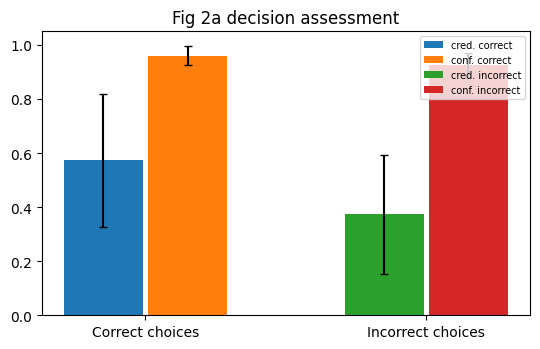

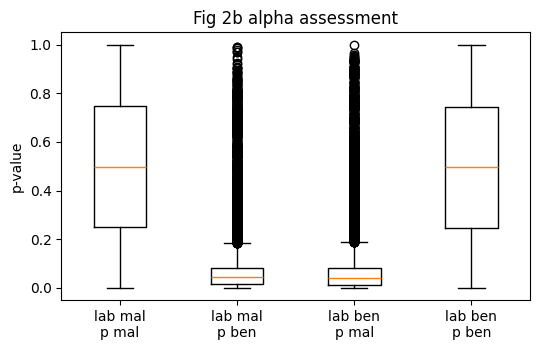


===== TABLE 3a: trained on early weeks, tested on later weeks (drift) =====
3a
            pred_benign pred_malicious  recall
  benign         39744           8256  0.83
  malicious      12528          35472  0.74
  precision       0.76           0.81

Thresholds (min kept 0.76): p-value tb=0.317 tm=0.296 (cal kept 0.76, F1 0.911) | prob tb=0.646 tm=0.634 (cal kept 0.76, F1 0.911)

===== TABLE 3b: drift test with threshold filtering =====
3b (p-value filtering)
            pred_benign pred_malicious  recall
  benign         33322           5482  0.86
  malicious       6698          29300  0.81
  precision       0.83           0.84
  kept 0.779  F1 0.837
3b' (probability filtering)
            pred_benign pred_malicious  recall
  benign         33166           5580  0.86
  malicious       6608          29732  0.82
  precision       0.83           0.84
  kept 0.782  F1 0.837

Batch A flagged by p-values: 10280 of 48000 (malicious 5892, benign 4388)

===== TABLE 3c: retraining simulation

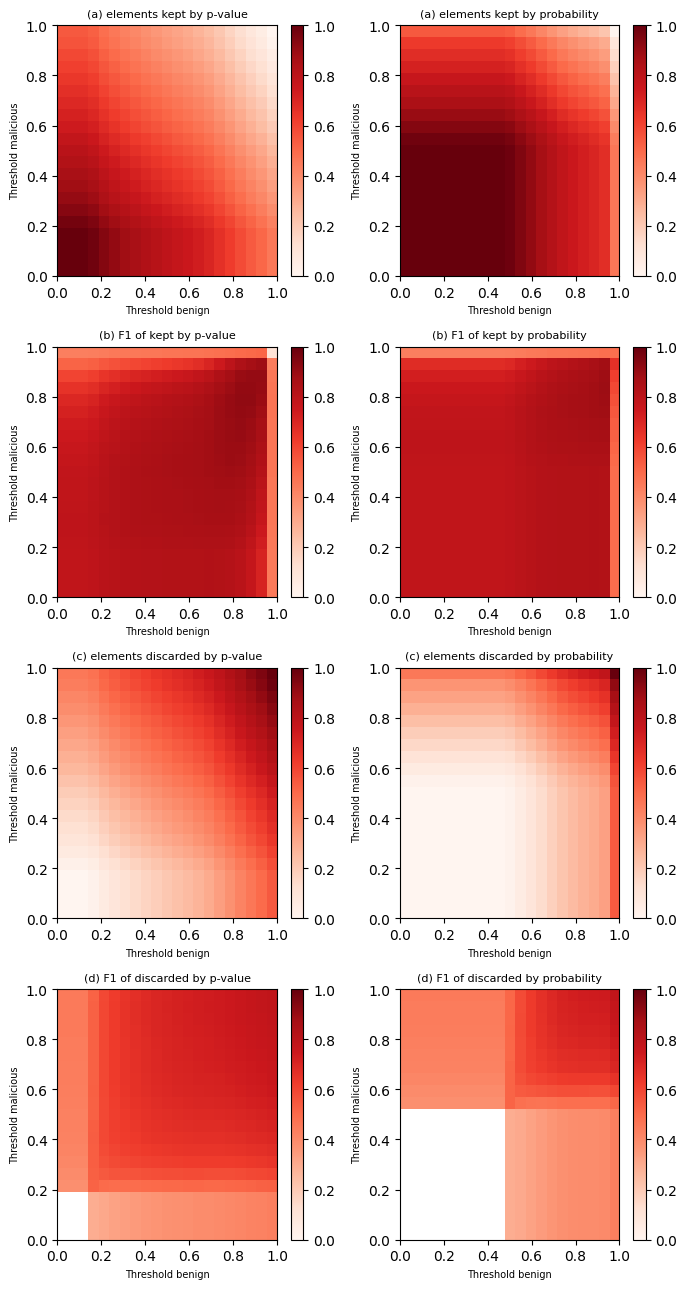

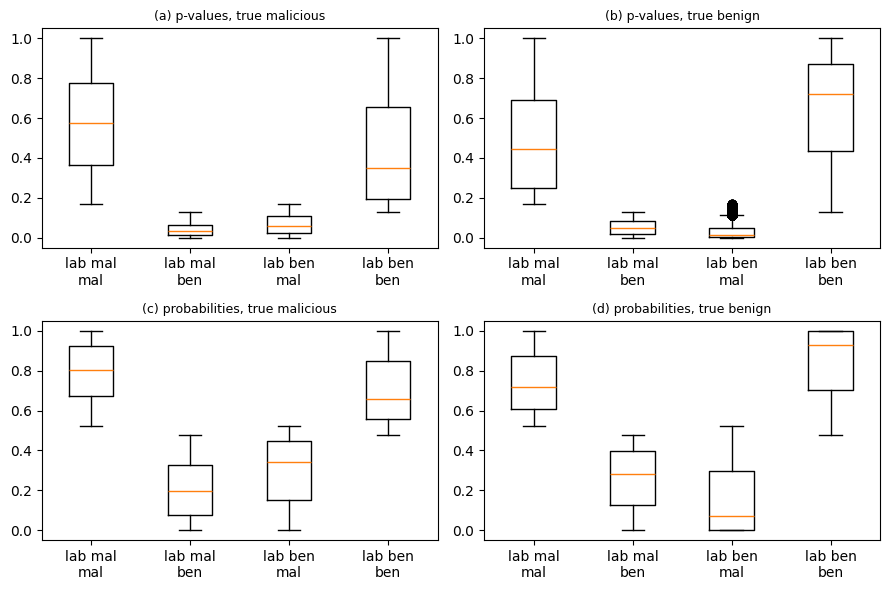

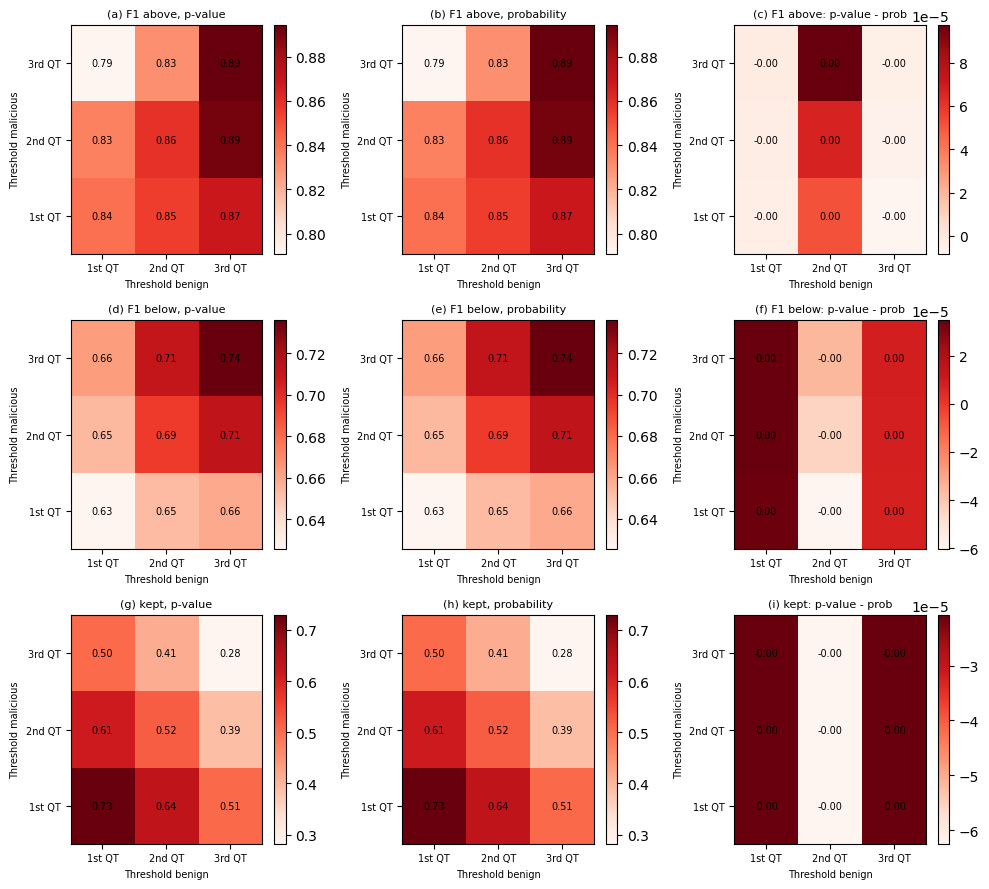


week | F1 all | F1 p-value kept | F1 prob kept | kept pv | kept prob
   1 | 0.807 | 0.856 | 0.859 | 0.788 | 0.795
   2 | 0.799 | 0.853 | 0.854 | 0.799 | 0.800
   3 | 0.771 | 0.829 | 0.830 | 0.785 | 0.784
   4 | 0.798 | 0.857 | 0.857 | 0.784 | 0.787
   5 | 0.796 | 0.854 | 0.854 | 0.777 | 0.777
   6 | 0.779 | 0.839 | 0.840 | 0.780 | 0.782
   7 | 0.767 | 0.808 | 0.807 | 0.782 | 0.785
   8 | 0.780 | 0.830 | 0.831 | 0.776 | 0.780
   9 | 0.760 | 0.820 | 0.819 | 0.767 | 0.772
  10 | 0.762 | 0.817 | 0.817 | 0.776 | 0.780
  11 | 0.795 | 0.839 | 0.841 | 0.774 | 0.778
  12 | 0.783 | 0.836 | 0.838 | 0.760 | 0.762
AVG: all 0.783 | p-value 0.837 | prob 0.837


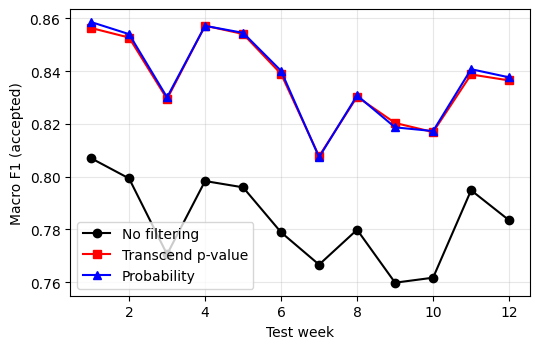


Done in 37s


In [ ]:
# Binary: Transcend drift test (Tables 3a-3c, 4; Figs 1, 2a/2b, 3, 6, weekly)
import os, numpy as np, matplotlib.pyplot as plt, time
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.preprocessing import StandardScaler
rng = np.random.default_rng(0); t0 = time.time()
NPZ = next(p for p in ["/content/apk_feats_full.npz", "/content/drive/MyDrive/apk_feats_full.npz"] if os.path.exists(p))
print("using:", NPZ)
EARLY, N_TRAIN_WEEKS = 12, 52
D = np.load(NPZ, allow_pickle=True); X, y, wk = D["X"], D["y"].astype(int), D["week"]
early = np.where(wk < EARLY)[0]; test = np.where(wk >= N_TRAIN_WEEKS)[0]
early = rng.permutation(early); n = len(early)
tr_i, cal_i, ev_i = early[:int(.6*n)], early[int(.6*n):int(.8*n)], early[int(.8*n):]
sc = StandardScaler().fit(X[tr_i])
Xtr, ytr = sc.transform(X[tr_i]), y[tr_i]; Xcal, ycal = sc.transform(X[cal_i]), y[cal_i]
Xev, yev = sc.transform(X[ev_i]), y[ev_i]; Xte, yte, wte = sc.transform(X[test]), y[test], wk[test] - N_TRAIN_WEEKS
print(f"train {len(tr_i)}  calib {len(cal_i)}  in-dist eval {len(ev_i)}  drift-test {len(test)}  (weeks 0-{EARLY-1} vs {N_TRAIN_WEEKS}-{N_TRAIN_WEEKS+11})")

def fit_svm(Xa, ya): return SGDClassifier(loss="hinge", alpha=1e-4, max_iter=30, tol=None, random_state=0).fit(Xa, ya)
svm = fit_svm(Xtr, ytr); print(f"[{time.time()-t0:.0f}s] SVM (linear, hinge) trained")
platt = LogisticRegression().fit(svm.decision_function(Xcal).reshape(-1, 1), ycal)

def ncm(Xs, l): s = svm.decision_function(Xs); return -s if l == 1 else s
cal_a = {l: np.sort(ncm(Xcal[ycal == l], l)) for l in (0, 1)}
def pvals(Xs):
    out = np.zeros((len(Xs), 2))
    for l in (0, 1):
        a = ncm(Xs, l); out[:, l] = (len(cal_a[l]) - np.searchsorted(cal_a[l], a, side="left")) / len(cal_a[l])
    return out
def probs(Xs): return platt.predict_proba(svm.decision_function(Xs).reshape(-1, 1))
def macro_f1(yt, yp):
    if len(yt) == 0: return np.nan
    f = []
    for c in (0, 1):
        tp = ((yp == c) & (yt == c)).sum(); fp = ((yp == c) & (yt != c)).sum(); fn = ((yp != c) & (yt == c)).sum()
        f.append(2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) > 0 else 0.0)
    return float(np.mean(f))
def cm(yt, yp): return np.array([[((yt==a)&(yp==b)).sum() for b in (0,1)] for a in (0,1)])
def show_cm(name, yt, yp):
    m = cm(yt, yp); rec = m.diagonal()/np.maximum(m.sum(1),1); pre = m.diagonal()/np.maximum(m.sum(0),1)
    print(f"{name}\n            pred_benign pred_malicious  recall\n  benign    {m[0,0]:10d} {m[0,1]:14d}  {rec[0]:.2f}\n  malicious {m[1,0]:10d} {m[1,1]:14d}  {rec[1]:.2f}\n  precision {pre[0]:10.2f} {pre[1]:14.2f}")
def save(n): plt.tight_layout(); plt.savefig(n, dpi=130); plt.show()
def bp(ax, data, labels):
    data = [d if len(d) else np.array([np.nan]) for d in data]; ax.boxplot(data, tick_labels=labels)

PVc, PRc = pvals(Xcal), probs(Xcal)
PVe, PRe = pvals(Xev), probs(Xev); pe = svm.predict(Xev)
PVt, PRt = pvals(Xte), probs(Xte); pt = svm.predict(Xte)
ar = lambda p: np.arange(len(p))

# ---- Fig 2a: decision assessment (in-distribution) ----
cred, conf = PVe[ar(pe), pe], 1 - PVe[ar(pe), 1-pe]; ok = pe == yev
vals = [(cred[ok].mean(), cred[ok].std()), (conf[ok].mean(), conf[ok].std()), (cred[~ok].mean(), cred[~ok].std()), (conf[~ok].mean(), conf[~ok].std())]
print("\nDecision assessment (in-dist): correct cred %.2f conf %.2f | incorrect cred %.2f conf %.2f" % (vals[0][0], vals[1][0], vals[2][0], vals[3][0]))
plt.figure(figsize=(5.5, 3.6)); xs = [0, .3, 1, 1.3]; cols = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
for x_, (m, s), c in zip(xs, vals, cols): plt.bar(x_, m, .28, yerr=s, color=c, capsize=3)
plt.xticks([.15, 1.15], ["Correct choices", "Incorrect choices"]); plt.ylim(0, 1.05)
plt.legend(["cred. correct", "conf. correct", "cred. incorrect", "conf. incorrect"], fontsize=7, loc="upper right"); plt.title("Fig 2a decision assessment"); save("p_fig2a_decision.png")
# ---- Fig 2b: alpha assessment (in-distribution) ----
fig, ax = plt.subplots(figsize=(5.5, 3.6))
bp(ax, [PVe[yev==1, 1], PVe[yev==1, 0], PVe[yev==0, 1], PVe[yev==0, 0]], ["lab mal\np mal", "lab mal\np ben", "lab ben\np mal", "lab ben\np ben"]); ax.set_ylabel("p-value"); ax.set_title("Fig 2b alpha assessment"); save("p_fig2b_alpha.png")

# ---- Table 3a ----
print("\n===== TABLE 3a: trained on early weeks, tested on later weeks (drift) ====="); show_cm("3a", yte, pt)

# ---- thresholds (Sec 3.3) ----
MIN_KEPT = 0.76
def kept_mask(score_pred, pred, tb, tm): return np.where(pred == 1, score_pred >= tm, score_pred >= tb)
def search(score_pred, pred, yt, min_kept):
    g = np.unique(np.quantile(score_pred, np.linspace(0, 0.5, 21))); best = (0, 0, -1, -1)
    for tb in g:
        for tm in g:
            k = kept_mask(score_pred, pred, tb, tm)
            if k.mean() < min_kept or k.sum() < 30: continue
            f = macro_f1(yt[k], pred[k])
            if f > best[3]: best = (tb, tm, k.mean(), f)
    return best
pc = svm.predict(Xcal)
sv_c, sp_c = PVc[ar(pc), pc], PRc[ar(pc), pc]
tb, tm, kc, fc = search(sv_c, pc, ycal, MIN_KEPT); tb2, tm2, kc2, fc2 = search(sp_c, pc, ycal, MIN_KEPT)
print(f"\nThresholds (min kept {MIN_KEPT}): p-value tb={tb:.3f} tm={tm:.3f} (cal kept {kc:.2f}, F1 {fc:.3f}) | prob tb={tb2:.3f} tm={tm2:.3f} (cal kept {kc2:.2f}, F1 {fc2:.3f})")
sv_t, sp_t = PVt[ar(pt), pt], PRt[ar(pt), pt]
k1, k2 = kept_mask(sv_t, pt, tb, tm), kept_mask(sp_t, pt, tb2, tm2)
print("\n===== TABLE 3b: drift test with threshold filtering ====="); show_cm("3b (p-value filtering)", yte[k1], pt[k1]); print(f"  kept {k1.mean():.3f}  F1 {macro_f1(yte[k1], pt[k1]):.3f}")
show_cm("3b' (probability filtering)", yte[k2], pt[k2]); print(f"  kept {k2.mean():.3f}  F1 {macro_f1(yte[k2], pt[k2]):.3f}")

# ---- Table 3c: retraining simulation ----
A, B = wte < 6, wte >= 6
disc = A & ~k1; print(f"\nBatch A flagged by p-values: {disc.sum()} of {A.sum()} (malicious {(yte[disc]==1).sum()}, benign {(yte[disc]==0).sum()})")
print("\n===== TABLE 3c: retraining simulation (test on batch B) ====="); show_cm("before retraining (batch B)", yte[B], pt[B])
svm_r = fit_svm(np.vstack([Xtr, Xte[disc]]), np.r_[ytr, yte[disc]]); pr_ = svm_r.predict(Xte[B]); show_cm("after retraining with Transcend-flagged samples", yte[B], pr_)
ridx = rng.choice(np.where(A)[0], disc.sum(), replace=False)
svm_rr = fit_svm(np.vstack([Xtr, Xte[ridx]]), np.r_[ytr, yte[ridx]]); prr = svm_rr.predict(Xte[B]); show_cm("EXTRA baseline: retraining with same number of RANDOM samples", yte[B], prr)
print(f"Batch B macro-F1: before {macro_f1(yte[B], pt[B]):.3f} | flagged-retrain {macro_f1(yte[B], pr_):.3f} | random-retrain {macro_f1(yte[B], prr):.3f}")

# ---- Table 4: quartile thresholds from true-positive distribution ----
def tp_scores(score_pred): return {l: score_pred[(ycal == l) & (pc == l)] for l in (0, 1)}
def stat_thr(sc_dict):
    f = {"1st quartile": lambda a: np.quantile(a, .25), "Median": np.median, "Mean": np.mean, "3rd quartile": lambda a: np.quantile(a, .75)}
    return {s: (f[s](sc_dict[0]), f[s](sc_dict[1])) for s in f}
thr_pv, thr_pr = stat_thr(tp_scores(sv_c)), stat_thr(tp_scores(sp_c))
def metrics(score_pred, thr):
    k = kept_mask(score_pred, pt, thr[0], thr[1]); out = []
    for m in (k, ~k):
        tpr = ((pt[m]==1)&(yte[m]==1)).sum()/max((yte[m]==1).sum(), 1); fpr = ((pt[m]==1)&(yte[m]==0)).sum()/max((yte[m]==0).sum(), 1); out += [tpr, fpr]
    out += [k[yte==1].mean(), k[yte==0].mean()]; return out
print("\n===== TABLE 4: thresholds from quartiles of true-positive scores =====")
print("columns: TPR/FPR of kept (p-value | prob) | TPR/FPR of discarded (p-value | prob) | malicious kept (pv | prob) | benign kept (pv | prob)")
for s in thr_pv:
    a, b = metrics(sv_t, thr_pv[s]), metrics(sp_t, thr_pr[s])
    print(f"{s:13s}| {a[0]:.3f}/{a[1]:.4f} | {b[0]:.3f}/{b[1]:.4f} | {a[2]:.3f}/{a[3]:.4f} | {b[2]:.3f}/{b[3]:.4f} | {a[4]:.3f} | {b[4]:.3f} | {a[5]:.3f} | {b[5]:.3f}")

# ---- Fig 1: threshold heatmaps ----
G = np.linspace(0, 1, 21); sets = {}
for nm, sc_ in (("p-value", sv_t), ("probability", sp_t)):
    kf, pk, df, pd_ = (np.full((21, 21), np.nan) for _ in range(4))
    for i, tm_ in enumerate(G):
        for j, tb_ in enumerate(G):
            k = kept_mask(sc_, pt, tb_, tm_); kf[i, j] = k.mean(); df[i, j] = 1 - k.mean()
            pk[i, j] = macro_f1(yte[k], pt[k]) if k.sum() > 20 else np.nan; pd_[i, j] = macro_f1(yte[~k], pt[~k]) if (~k).sum() > 20 else np.nan
    sets[nm] = (kf, pk, df, pd_)
fig, axs = plt.subplots(4, 2, figsize=(7, 13)); titles = ["(a) elements kept", "(b) F1 of kept", "(c) elements discarded", "(d) F1 of discarded"]
for r in range(4):
    for c, nm in enumerate(("p-value", "probability")):
        im = axs[r, c].imshow(sets[nm][r], origin="lower", extent=[0, 1, 0, 1], aspect="auto", cmap="Reds", vmin=0, vmax=1); axs[r, c].set_title(f"{titles[r]} by {nm}", fontsize=8)
        axs[r, c].set_xlabel("Threshold benign", fontsize=7); axs[r, c].set_ylabel("Threshold malicious", fontsize=7); plt.colorbar(im, ax=axs[r, c])
save("p_fig1_heatmaps.png")

# ---- Fig 3: score distributions under drift ----
fig, axs = plt.subplots(2, 2, figsize=(9, 6))
for ax, (M, ttl, tl) in zip(axs.ravel(), [(PVt, "(a) p-values, true malicious", 1), (PVt, "(b) p-values, true benign", 0), (PRt, "(c) probabilities, true malicious", 1), (PRt, "(d) probabilities, true benign", 0)]):
    s = yte == tl; bp(ax, [M[s & (pt == 1), 1], M[s & (pt == 1), 0], M[s & (pt == 0), 1], M[s & (pt == 0), 0]], ["lab mal\nmal", "lab mal\nben", "lab ben\nmal", "lab ben\nben"]); ax.set_title(ttl, fontsize=9)
save("p_fig3_distributions.png")

# ---- Fig 6: quartile-grid comparison ----
qn = ["1st QT", "2nd QT", "3rd QT"]; qk = ["1st quartile", "Median", "3rd quartile"]
def grid(score, thr_d):
    perf = np.full((3, 3), np.nan); perf_b = perf.copy(); frac = perf.copy()
    for i, sm in enumerate(qk):
        for j, sb in enumerate(qk):
            k = kept_mask(score, pt, thr_d[sb][0], thr_d[sm][1]); perf[i, j] = macro_f1(yte[k], pt[k]); perf_b[i, j] = macro_f1(yte[~k], pt[~k]); frac[i, j] = k.mean()
    return perf, perf_b, frac
gp, gpb, gf = grid(sv_t, thr_pv); qp, qpb, qf = grid(sp_t, thr_pr)
panels = [("(a) F1 above, p-value", gp), ("(b) F1 above, probability", qp), ("(c) F1 above: p-value - prob", gp - qp),
          ("(d) F1 below, p-value", gpb), ("(e) F1 below, probability", qpb), ("(f) F1 below: p-value - prob", gpb - qpb),
          ("(g) kept, p-value", gf), ("(h) kept, probability", qf), ("(i) kept: p-value - prob", gf - qf)]
fig, axs = plt.subplots(3, 3, figsize=(10, 9))
for ax, (t, M) in zip(axs.ravel(), panels):
    im = ax.imshow(M, origin="lower", cmap="Reds", aspect="auto"); ax.set_title(t, fontsize=8); ax.set_xticks(range(3)); ax.set_xticklabels(qn, fontsize=7); ax.set_yticks(range(3)); ax.set_yticklabels(qn, fontsize=7)
    ax.set_xlabel("Threshold benign", fontsize=7); ax.set_ylabel("Threshold malicious", fontsize=7); plt.colorbar(im, ax=ax)
    for a in range(3):
        for b in range(3): ax.text(b, a, f"{M[a,b]:.2f}", ha="center", va="center", fontsize=7)
save("p_fig6_quartile_grid.png")

# ---- weekly view ----
rows = []
for w in range(12):
    s = wte == w; rows.append((w+1, macro_f1(yte[s], pt[s]), macro_f1(yte[s & k1], pt[s & k1]), macro_f1(yte[s & k2], pt[s & k2]), k1[s].mean(), k2[s].mean()))
R = np.array(rows); print("\nweek | F1 all | F1 p-value kept | F1 prob kept | kept pv | kept prob")
for r in R: print("%4d | %.3f | %.3f | %.3f | %.3f | %.3f" % tuple(r))
print("AVG: all %.3f | p-value %.3f | prob %.3f" % (R[:,1].mean(), np.nanmean(R[:,2]), np.nanmean(R[:,3])))
plt.figure(figsize=(5.5, 3.6)); plt.plot(R[:,0], R[:,1], "k-o", label="No filtering"); plt.plot(R[:,0], R[:,2], "r-s", label="Transcend p-value"); plt.plot(R[:,0], R[:,3], "b-^", label="Probability")
plt.xlabel("Test week"); plt.ylabel("Macro F1 (accepted)"); plt.legend(); plt.grid(alpha=.3); save("p_fig_weekly.png")
print(f"\nDone in {time.time()-t0:.0f}s")

using: /content/apk_feats_full.npz
Top malware families: [('jiagu', 19026), ('spymax', 14214), ('wapron', 13814), ('mobidash', 7998), ('metasploit', 7282), ('boogr', 6558), ('hiddad', 6488), ('adlo', 6212), ('robtes', 5846), ('wacatac', 5292), ('spyloan', 4354), ('fakecalls', 3794), ('fyben', 3300), ('hary', 3224), ('smsreg', 3076)]
Known (trained): ['jiagu', 'spymax', 'wapron', 'metasploit', 'boogr', 'hiddad', 'adlo'] 
Held-out (novel): mobidash
[70s] RF trained on 12600 samples, 7 families

Known-family test accuracy: 0.925
Confusion matrix (rows true, cols predicted):
               jiagu   spymax   wapron  metaspl    boogr   hiddad     adlo
jiagu            574        1        3        3        7       12        0
spymax            25      530        0        8       23       14        0
wapron             2        0      594        0        2        2        0
metasploit        17        3        0      539       27       14        0
boogr             34        8        0       11

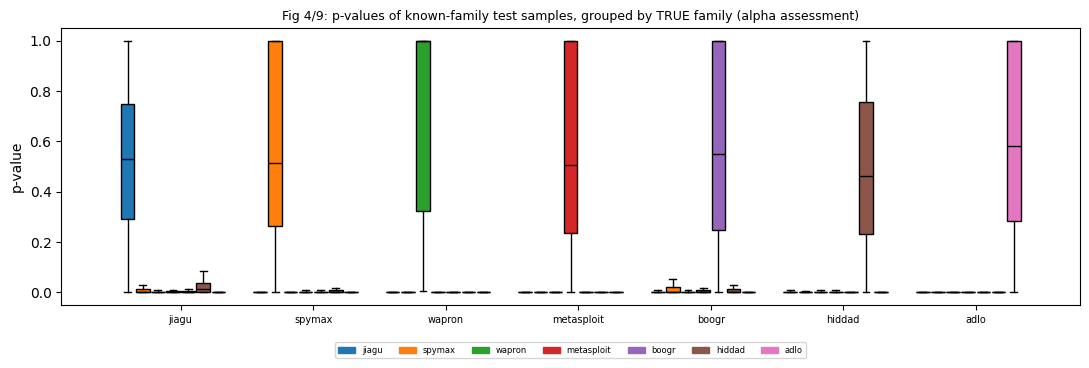

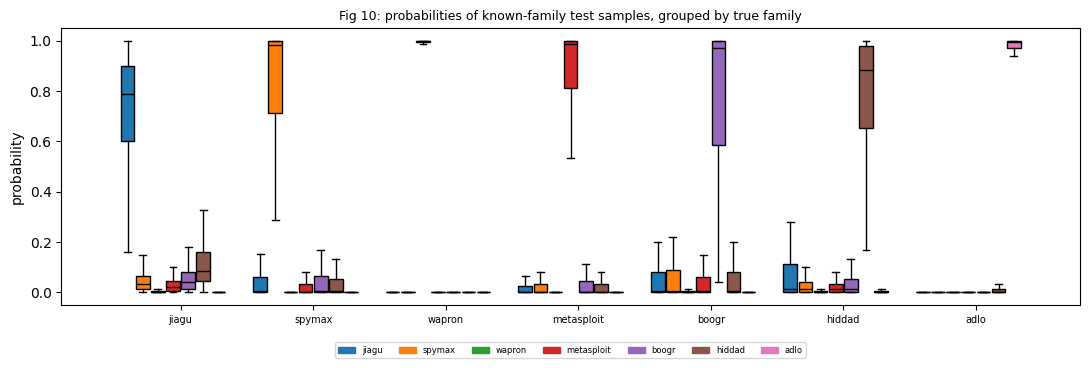

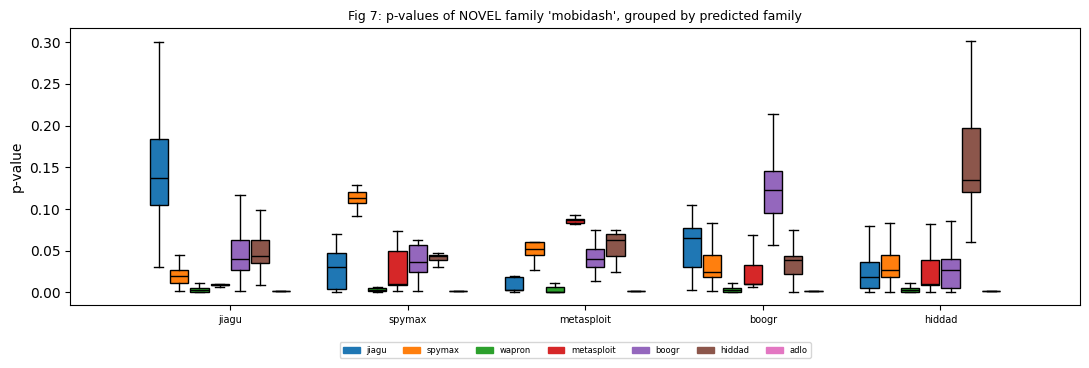

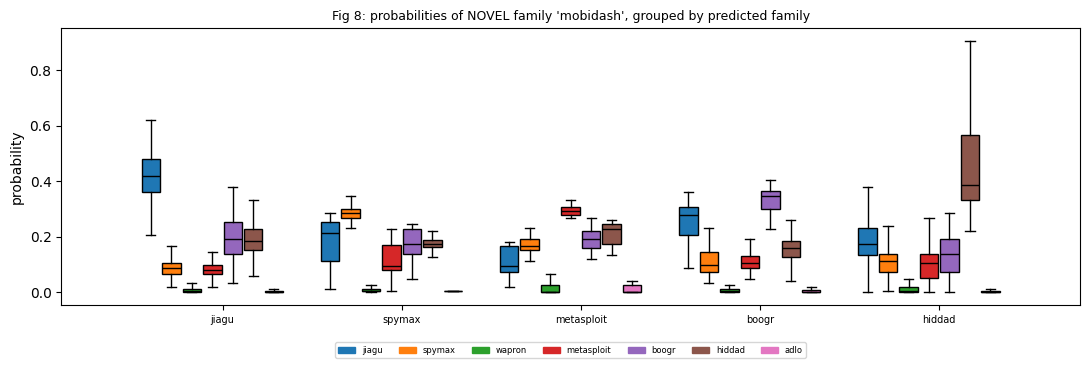

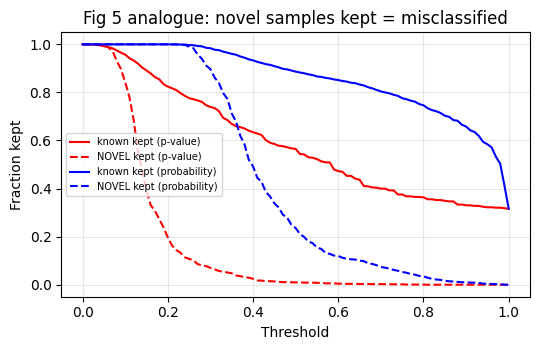


Thresholds from quartiles of calibration true-positive scores (per class):
stat          | known kept pv | known kept prob | NOVEL flagged pv | NOVEL flagged prob
1st quartile  | 0.727 | 0.727 | 0.948 | 0.948
Median        | 0.526 | 0.526 | 0.992 | 0.992
3rd quartile  | 0.368 | 0.368 | 0.999 | 0.999

AUROC novel-vs-known: p-value credibility 0.883 | max probability 0.917
Done in 75s


In [ ]:
# Multiclass: Naya family detect, mobidash (Table 4; Figs 4/9, 5, 7, 8, 10)
import numpy as np, matplotlib.pyplot as plt, time
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(0); t0 = time.time()
import os
NPZ = next(p for p in ["/content/apk_feats_full.npz", "/content/drive/MyDrive/apk_feats_full.npz"] if os.path.exists(p))
print("using:", NPZ)
K_FAM, HOLD_RANK, MIN_PER_FAM, CAP = 8, 3, 300, 3000
D = np.load(NPZ, allow_pickle=True); X, y, fam = D["X"], D["y"].astype(int), D["family"].astype(str)
isfam = (y == 1) & ~np.isin(np.char.lower(fam), ["none", "", "nan", "null"])
names, cnt = np.unique(fam[isfam], return_counts=True); names = [str(n) for n in names]; o = np.argsort(-cnt)
print("Top malware families:", [(names[i], int(cnt[i])) for i in o[:15]])
top = [names[i] for i in o if cnt[i] >= MIN_PER_FAM][:K_FAM]
assert len(top) >= 4, "not enough families with >= MIN_PER_FAM samples: lower MIN_PER_FAM"
hold = top[min(HOLD_RANK, len(top) - 1)]; known = [f for f in top if f != hold]
print("Known (trained):", known, "\nHeld-out (novel):", hold)
def take(f):
    idx = np.where(isfam & (fam == f))[0]; return rng.permutation(idx)[:CAP]
parts = [take(f) for f in known]; idx_k = np.concatenate(parts); yk = np.concatenate([np.full(len(p), i) for i, p in enumerate(parts)])
Xn_all = X[take(hold)]
tr, rest, ytr, yrest = train_test_split(idx_k, yk, test_size=0.4, stratify=yk, random_state=0)
cal, te, ycal, yte = train_test_split(rest, yrest, test_size=0.5, stratify=yrest, random_state=0)
rf = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=0).fit(X[tr], ytr); print(f"[{time.time()-t0:.0f}s] RF trained on {len(tr)} samples, {len(known)} families")
K = len(known)
cal_a = [np.sort(-rf.predict_proba(X[cal])[ycal == c, c]) for c in range(K)]
def pvals(P): return np.stack([(len(cal_a[c]) - np.searchsorted(cal_a[c], -P[:, c], side="left")) / len(cal_a[c]) for c in range(K)], 1)
Pk, Pn = rf.predict_proba(X[te]), rf.predict_proba(Xn_all); PVk, PVn = pvals(Pk), pvals(Pn); pk, pn = Pk.argmax(1), Pn.argmax(1)
ar = lambda p: np.arange(len(p))
print(f"\nKnown-family test accuracy: {(pk == yte).mean():.3f}")
m = np.array([[((yte == a) & (pk == b)).sum() for b in range(K)] for a in range(K)]); print("Confusion matrix (rows true, cols predicted):"); print(" " * 12 + " ".join(f"{k[:7]:>8s}" for k in known))
for i, k in enumerate(known): print(f"{k[:11]:11s} " + " ".join(f"{v:8d}" for v in m[i]))
print(f"\nNovel family '{hold}' ({len(pn)} samples) was classified as:", {known[i]: int((pn == i).sum()) for i in range(K) if (pn == i).sum()})
print("Mean credibility: known %.3f | novel %.3f  ||  mean max-probability: known %.3f | novel %.3f" % (PVk[ar(pk), pk].mean(), PVn[ar(pn), pn].mean(), Pk.max(1).mean(), Pn.max(1).mean()))
def save(n): plt.tight_layout(); plt.savefig(n, dpi=130); plt.show()
cols = plt.cm.tab10(np.arange(K))
def grouped_box(M, groups, title, fname, ylab):
    fig, ax = plt.subplots(figsize=(11, 3.8)); present = [g for g in range(K) if (groups == g).any()]; w = 0.8 / K
    for gi, g in enumerate(present):
        for c in range(K):
            b = ax.boxplot(M[groups == g, c], positions=[gi + (c - K/2) * w], widths=w * 0.9, patch_artist=True, showfliers=False)
            b["boxes"][0].set_facecolor(cols[c]); [x.set_color("k") for x in b["medians"]]
    ax.set_xticks(range(len(present))); ax.set_xticklabels([known[g][:10] for g in present], fontsize=7); ax.set_ylabel(ylab); ax.set_title(title, fontsize=9)
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=cols[c]) for c in range(K)], [k[:10] for k in known], fontsize=6, ncol=K, loc="upper center", bbox_to_anchor=(.5, -0.12)); save(fname)
grouped_box(PVk, yte, "Fig 4/9: p-values of known-family test samples, grouped by TRUE family (alpha assessment)", "m_fig4_9_alpha_known.png", "p-value")
grouped_box(Pk, yte, "Fig 10: probabilities of known-family test samples, grouped by true family", "m_fig10_prob_known.png", "probability")
grouped_box(PVn, pn, f"Fig 7: p-values of NOVEL family '{hold}', grouped by predicted family", "m_fig7_pvalues_novel.png", "p-value")
grouped_box(Pn, pn, f"Fig 8: probabilities of NOVEL family '{hold}', grouped by predicted family", "m_fig8_prob_novel.png", "probability")
Ts = np.linspace(0, 1, 101); credk, credn = PVk[ar(pk), pk], PVn[ar(pn), pn]
prk, prn = Pk.max(1), Pn.max(1)
plt.figure(figsize=(5.5, 3.6))
plt.plot(Ts, [(credk >= t).mean() for t in Ts], "r-", label="known kept (p-value)"); plt.plot(Ts, [(credn >= t).mean() for t in Ts], "r--", label="NOVEL kept (p-value)")
plt.plot(Ts, [(prk >= t).mean() for t in Ts], "b-", label="known kept (probability)"); plt.plot(Ts, [(prn >= t).mean() for t in Ts], "b--", label="NOVEL kept (probability)")
plt.xlabel("Threshold"); plt.ylabel("Fraction kept"); plt.legend(fontsize=7); plt.grid(alpha=.3); plt.title("Fig 5 analogue: novel samples kept = misclassified"); save("m_fig5_kept_curves.png")
Pc = rf.predict_proba(X[cal]); PVc = pvals(Pc); pc = Pc.argmax(1)
print("\nThresholds from quartiles of calibration true-positive scores (per class):")
print("stat          | known kept pv | known kept prob | NOVEL flagged pv | NOVEL flagged prob")
for nm, fn in (("1st quartile", lambda a: np.quantile(a, .25)), ("Median", np.median), ("3rd quartile", lambda a: np.quantile(a, .75))):
    tpv = np.array([fn(PVc[(ycal == c) & (pc == c), c]) for c in range(K)]); tpr = np.array([fn(Pc[(ycal == c) & (pc == c), c]) for c in range(K)])
    kk_pv, kk_pr = (credk >= tpv[pk]).mean(), (prk >= tpr[pk]).mean(); nf_pv, nf_pr = (credn < tpv[pn]).mean(), (prn < tpr[pn]).mean()
    print(f"{nm:13s} | {kk_pv:.3f} | {kk_pr:.3f} | {nf_pv:.3f} | {nf_pr:.3f}")
yy = np.r_[np.zeros(len(credk)), np.ones(len(credn))]
print("\nAUROC novel-vs-known: p-value credibility %.3f | max probability %.3f" % (roc_auc_score(yy, -np.r_[credk, credn]), roc_auc_score(yy, -np.r_[prk, prn])))
print(f"Done in {time.time()-t0:.0f}s")